# Protocolo y validación estadística

¿RegionalMAPEM predice mejor que el mejor benchmark? Este capítulo responde con el protocolo que congelamos antes de
correr los experimentos definitivos. La respuesta corta es que no: en Telco empata con la logística con splines, le gana
con claridad a 7 de los 11 benchmarks y no cumple la definición de superioridad que fijamos. Lo que sigue muestra cómo
llegamos a esa conclusión y por qué es sólida.

## El protocolo

El diseño quedó fijado en [`experiments/protocolo.md`](https://github.com/Nataly-Cardenas/Telco_Churn_Entregable/blob/main/experiments/protocolo.md)
con el tag de Git `protocolo-v1` (8 de noviembre de 2026, 16:13), antes de evaluar un solo pliegue externo. Sus puntos
centrales:

| Elemento | Decisión |
|---|---|
| Hipótesis principal (H1) | RegionalMAPEM tiene menor log-loss medio externo que el mejor benchmark en Telco |
| Métrica principal | Log-loss. La elegimos después de los pilotos, y así quedó declarado: mide la calidad de la probabilidad, que es lo que combina el modelo |
| Métricas secundarias | F1 de la clase churn y AUC, que también entran en la corrección por comparaciones múltiples |
| Particiones | Validación anidada {cite}`cawley2010` 5 × 5 en Telco (5634 clientes de desarrollo), 3 pliegues internos; el hold-out de 1409 clientes se evalúa una sola vez al final |
| Presupuesto | 30 evaluaciones de Optuna {cite}`akiba2019` con TPE {cite}`bergstra2011` por modelo y pliegue, con el mismo punto de partida recomendado |
| Calibración | Platt {cite}`platt1999` dentro del bucle interno para todos los modelos; sin SMOTE |
| Pruebas | Nadeau-Bengio {cite}`nadeau2003` (T1), permutación pareada de signos (T2), Friedman con Iman-Davenport {cite}`iman1980` y Nemenyi {cite}`demsar2006` (T3), Wilcoxon (T4), DeLong {cite}`delong1988` y McNemar {cite}`mcnemar1947` en el hold-out |
| Comparaciones múltiples | Holm {cite}`holm1979` sobre una sola familia de 223 comparaciones, con α = 0,05 |
| Tamaño del efecto | δ de Cliff, con el umbral de 0,147 de {cite:t}`romano2006` |

Las desviaciones posteriores al tag están registradas en la sección 12 del protocolo. Ninguna cambia qué se calcula:

| # | Qué pasó | Efecto |
|---|---|---|
| D1 | La corrida con 16 procesos se cayó por falta de recursos del sistema y se relanzó con 10 | Ninguno: cada tarea tiene semilla fija; tres tareas repetidas coinciden bit a bit con sus checkpoints |
| D2 | Se silenció el registro de Optuna | Solo cambia lo que se imprime |
| D3 | Los scripts de análisis se escribieron después del tag y se corrigieron antes de usarse (procesos, semillas de SHAP, un `Pipeline` anidado) | Ninguno sobre la familia confirmatoria |
| D4 | La escalabilidad se midió con un solo proceso | Tiempos comparables entre modelos |
| D5 | El análisis de los cuatro conjuntos se selló con SHA-256 antes de abrir el hold-out | Trazabilidad |
| D6 | Monitor de solo lectura durante la corrida | Ninguno |
| D7 | En SHAP, `TotalCharges` vacío pasa a 0 antes de explicar | Ninguno sobre clientes reales |

El sello de D5 se puede comprobar: las tablas de `experiments/resultados/tablas_pre_holdout/` coinciden con las huellas
de `sello_pre_holdout.json`, y al sumar las tres pruebas del hold-out ningún p crudo de las otras 220 comparaciones cambió
ni ninguna decisión de Holm se invirtió.

In [1]:
# Configuración: solo se leen tablas versionadas; nada se reentrena.
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
from src.presentacion import tabla, nota, estilo_figuras, numero, valor_p, NOMBRES, CONJUNTOS, AZUL, RIESGO, ACENTO, GRIS
estilo_figuras()
TAB = ROOT / "experiments" / "resultados" / "tablas"
FAM = pd.read_csv(TAB / "familia_resultados.csv")            # las 223 comparaciones con p crudo y p de Holm
POR_PLIEGUE = pd.read_csv(TAB / "metricas_por_pliegue.csv")    # métricas de cada modelo en cada pliegue externo
RESUMEN = pd.read_csv(TAB / "resumen_modelos.csv")
COSTOS = pd.read_csv(TAB / "costos_por_pliegue.csv")
VEREDICTO = json.loads((TAB / "veredicto_R3.json").read_text(encoding="utf-8"))
FRIEDMAN = json.loads((TAB / "friedman_telco.json").read_text(encoding="utf-8"))
MEJOR = VEREDICTO["mejor_benchmark"]["telco"]

# Comprobación del sello previo al hold-out (desviación D5)
import hashlib
sello = json.loads((ROOT / "experiments/resultados/sello_pre_holdout.json").read_text(encoding="utf-8"))
intactas = all(hashlib.sha256((ROOT / "experiments/resultados/tablas_pre_holdout" / k).read_bytes()).hexdigest() == v
               for k, v in sello["archivos"].items())
nota(f"<b>Sello previo al hold-out:</b> {len(sello['archivos'])} tablas fechadas el {sello['fecha'][:16].replace('T', ' a las ')}, "
     f"{'todas intactas' if intactas else 'ALGUNA MODIFICADA'}.", "ok" if intactas else "warn")

## Equidad de la comparación

Una ventaja solo significa algo si todos los modelos tuvieron las mismas oportunidades. Cada benchmark y el modelo propio
recibieron 30 evaluaciones de hiperparámetros en cada pliegue externo, con el mismo preprocesamiento (ajustado dentro de
cada pliegue), las mismas particiones, la misma calibración de Platt y la misma métrica de búsqueda. La tabla muestra el
presupuesto realmente consumido en Telco: ningún ensayo falló y todos los modelos usaron sus 30 evaluaciones. Lo que
cambia entre modelos es el tiempo, no el número de oportunidades.

In [2]:
# Presupuesto consumido en Telco, promedio por pliegue externo (25 pliegues)
c = COSTOS[COSTOS.conjunto == "telco"].groupby("modelo").agg(
    ensayos=("ensayos", "mean"), fallidos=("fallidos", "sum"), busqueda=("seg_busqueda", "mean"),
    ajuste=("seg_ajuste", "mean"), pred=("seg_pred_por_1000", "mean")).reset_index()
c = c.sort_values("busqueda")
vista = pd.DataFrame({
    "Modelo": c.modelo.map(NOMBRES), "Evaluaciones por pliegue": c.ensayos.round().astype(int),
    "Evaluaciones fallidas (total)": c.fallidos.astype(int), "Búsqueda (min)": c.busqueda / 60,
    "Ajuste final (s)": c.ajuste, "Predicción (ms por 1000 clientes)": 1000 * c.pred})
tabla(vista, "Tabla 6.1. Presupuesto de optimización consumido en Telco", decimales=2,
      nota="Medias por pliegue externo. La búsqueda incluye los 3 pliegues internos y la calibración. En RegionalMAPEM "
           "solo cuenta la combinación: sus expertos son los benchmarks ya ajustados.")

Modelo,Evaluaciones por pliegue,Evaluaciones fallidas (total),Búsqueda (min),Ajuste final (s),Predicción (ms por 1000 clientes)
Naive Bayes,30,0,"0,83","0,43","122,46"
Árbol de decisión,30,0,"0,90","0,50","105,11"
Logística con splines,30,0,"1,02","0,64","115,75"
Logística,30,0,"1,68","0,92","115,25"
kNN,30,0,"2,08","1,21","600,31"
XGBoost,30,0,"3,53","2,11","132,31"
LightGBM,30,0,"4,10","2,35","333,03"
SVM,30,0,"4,56","3,32","1.024,38"
HistGB,30,0,"9,42","4,43","449,34"
RegionalMAPEM,30,0,"11,03","8,42","5,81"


CatBoost y Random Forest son los más caros de ajustar; la logística con splines, el mejor benchmark, es de los más
baratos. El modelo propio parece rápido porque reutiliza las predicciones fuera de pliegue de los expertos, pero en
producción arrastra el costo de los once.

## Resultados en Telco

La tabla 6.2 resume los 25 pliegues externos. Para el log-loss se agrega el intervalo de confianza BCa del 95 % de la
media por pliegue.

In [3]:
# Resumen del bucle externo en Telco: media ± desviación estándar sobre los 25 pliegues
r = RESUMEN[RESUMEN.conjunto == "telco"].sort_values("log_loss_media")
tiempos = COSTOS[COSTOS.conjunto == "telco"].groupby("modelo")[["seg_ajuste", "seg_pred_por_1000"]].mean()
f = lambda m, k: f"{numero(m[k + '_media'], 4)} ± {numero(m[k + '_de'], 4)}"
vista = pd.DataFrame({
    "Modelo": r.modelo.map(NOMBRES),
    "Log-loss": [f(m, "log_loss") for _, m in r.iterrows()],
    "IC 95 % (BCa)": [f"[{numero(a, 4)}; {numero(b, 4)}]" for a, b in zip(r.log_loss_ic_bajo, r.log_loss_ic_alto)],
    "F1": [f(m, "f1") for _, m in r.iterrows()], "AUC": [f(m, "auc") for _, m in r.iterrows()],
    "Brier": [f(m, "brier") for _, m in r.iterrows()], "ECE": [f(m, "ece") for _, m in r.iterrows()],
    "Ajuste (s)": r.modelo.map(tiempos.seg_ajuste),
    "Predicción (ms / 1000)": r.modelo.map(1000 * tiempos.seg_pred_por_1000)})
tabla(vista, "Tabla 6.2. Modelo propio, variantes de ablación y benchmarks en Telco (25 pliegues externos)", decimales=2,
      nota="Ordenada por log-loss. Ajuste y predicción: medias por pliegue; en los combinadores no incluyen a los expertos.")

Modelo,Log-loss,IC 95 % (BCa),F1,AUC,Brier,ECE,Ajuste (s),Predicción (ms / 1000)
Pesos globales (K = 1),"0,4109 ± 0,0088","[0,4073; 0,4142]","0,6337 ± 0,0121","0,8503 ± 0,0080","0,1330 ± 0,0036","0,0252 ± 0,0064",—,—
Stacking logístico,"0,4112 ± 0,0096","[0,4074; 0,4147]","0,6359 ± 0,0129","0,8503 ± 0,0080","0,1331 ± 0,0039","0,0273 ± 0,0075",—,—
RegionalMAPEM,"0,4113 ± 0,0092","[0,4076; 0,4147]","0,6342 ± 0,0121","0,8501 ± 0,0083","0,1331 ± 0,0037","0,0254 ± 0,0053","8,42","5,81"
Logística con splines,"0,4113 ± 0,0091","[0,4076; 0,4147]","0,6379 ± 0,0138","0,8498 ± 0,0081","0,1330 ± 0,0035","0,0243 ± 0,0057","0,64","115,75"
Regiones duras,"0,4114 ± 0,0092","[0,4078; 0,4148]","0,6347 ± 0,0128","0,8500 ± 0,0083","0,1331 ± 0,0037","0,0251 ± 0,0063",—,—
MAP-EM sin prior,"0,4117 ± 0,0093","[0,4080; 0,4152]","0,6340 ± 0,0138","0,8497 ± 0,0082","0,1332 ± 0,0038","0,0266 ± 0,0051",—,—
LightGBM,"0,4123 ± 0,0088","[0,4090; 0,4157]","0,6328 ± 0,0117","0,8491 ± 0,0077","0,1335 ± 0,0035","0,0272 ± 0,0067","2,35","333,03"
HistGB,"0,4127 ± 0,0085","[0,4094; 0,4160]","0,6320 ± 0,0131","0,8489 ± 0,0076","0,1337 ± 0,0035","0,0253 ± 0,0069","4,43","449,34"
Promedio simple,"0,4152 ± 0,0088","[0,4116; 0,4185]","0,6320 ± 0,0131","0,8494 ± 0,0081","0,1338 ± 0,0038","0,0311 ± 0,0074",—,—
Logística,"0,4171 ± 0,0085","[0,4138; 0,4203]","0,6349 ± 0,0146","0,8457 ± 0,0077","0,1352 ± 0,0033","0,0244 ± 0,0080","0,92","115,25"


Las diferencias de la parte alta son minúsculas. RegionalMAPEM (0,41127) queda a 0,00003 de la logística con splines
(0,41130), menos de una décima parte de la desviación estándar entre pliegues. Por delante quedan dos combinadores más
simples: los pesos globales ($K = 1$) y el stacking logístico. Todos los combinadores calibrados superan a los modelos
individuales clásicos, y la calibración es buena en general (ECE entre 0,024 y 0,045), resultado del Platt interno.

### Diagrama de diferencia crítica

Friedman con la corrección de Iman-Davenport compara los rangos de los 17 modelos en los 25 pliegues. El diagrama
une con una barra los modelos cuya diferencia de rango medio es menor que la diferencia crítica de Nemenyi.

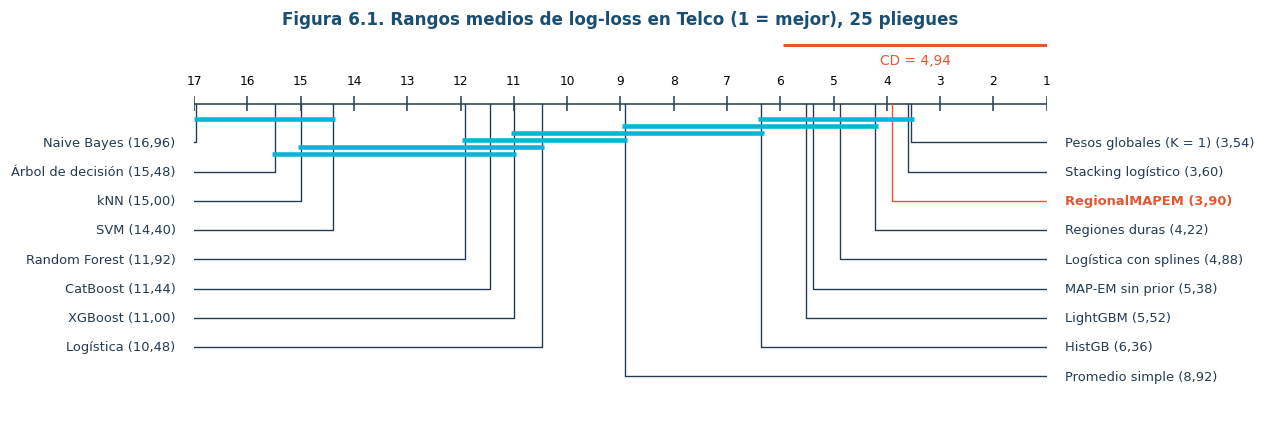

Estadístico de Iman-Davenport (F_F),p,Modelos (k),Pliegues (N),"Diferencia crítica de Nemenyi (α = 0,05)"
"139,685","5,96e−149",17,25,"4,940"


In [4]:
# Diagrama de diferencia crítica (Demšar, 2006) con los rangos de Friedman en Telco
def diagrama_cd(rangos, cd, titulo):
    nombres = sorted(rangos, key=rangos.get); k = len(nombres); R = np.array([rangos[n] for n in nombres])
    fig, ax = plt.subplots(figsize=(10, 4.6)); ax.set_xlim(1, k); ax.set_ylim(0, 1); ax.invert_xaxis(); ax.axis("off")
    ax.hlines(0.82, 1, k, color="#243B53", lw=1)
    for t in range(1, k + 1):
        ax.vlines(t, 0.80, 0.84, color="#243B53", lw=1); ax.text(t, 0.87, str(t), ha="center", fontsize=8)
    ax.hlines(0.97, 1, 1 + cd, color=RIESGO, lw=2); ax.text(1 + cd / 2, 0.92, f"CD = {cd:.2f}".replace(".", ","), ha="center", fontsize=9, color=RIESGO)
    mitad = (k + 1) // 2
    for i, (n, x) in enumerate(zip(nombres, R)):
        izquierda = i < mitad; y = 0.72 - 0.075 * (i if izquierda else k - 1 - i)
        xt = 1 - 0.2 if izquierda else k + 0.2
        color = RIESGO if n == "RegionalMAPEM" else "#243B53"
        ax.plot([x, x, xt], [0.82, y, y], color=color, lw=0.9)
        ax.text(xt + (-0.15 if izquierda else 0.15), y, f"{NOMBRES[n]} ({x:.2f})".replace(".", ","),
                ha="left" if izquierda else "right", va="center", fontsize=8.5, color=color, fontweight="bold" if color == RIESGO else None)
    # grupos sin diferencia significativa: barras horizontales
    grupos, nivel = [], 0
    for i in range(k):
        j = max(jj for jj in range(i, k) if R[jj] - R[i] < cd)
        if j > i and not any(a <= i and j <= b for a, b in grupos):
            grupos.append((i, j))
    for a, b in grupos:
        ax.hlines(0.78 - 0.018 * nivel, R[a] - 0.05, R[b] + 0.05, color=ACENTO, lw=3); nivel = (nivel + 1) % 6
    ax.set_title(titulo); plt.show()

diagrama_cd(FRIEDMAN["rangos"], FRIEDMAN["CD"], "Figura 6.1. Rangos medios de log-loss en Telco (1 = mejor), 25 pliegues")
tabla(pd.DataFrame([{"Estadístico de Iman-Davenport (F_F)": FRIEDMAN["F_F"], "p": FRIEDMAN["p"], "Modelos (k)": FRIEDMAN["k"],
                     "Pliegues (N)": FRIEDMAN["N"], "Diferencia crítica de Nemenyi (α = 0,05)": FRIEDMAN["CD"]}]),
      "Tabla 6.3. Prueba de Friedman con corrección de Iman-Davenport en Telco", decimales=3, columnas_p=("p",), buscar=False)

Friedman rechaza con holgura que todos los modelos sean iguales, así que tiene sentido mirar los pares. RegionalMAPEM
tiene rango medio 3,90 y la logística con splines 4,88: la distancia (0,98) está muy por debajo de la diferencia crítica
de 4,94. En cambio, Naive Bayes, el árbol, kNN, SVM, Random Forest, CatBoost y XGBoost quedan a más de esa distancia,
y Nemenyi confirma esas siete diferencias después de Holm.

### Pruebas frente al mejor benchmark

El mejor benchmark se define, como en el protocolo, por el menor log-loss medio externo entre los 11: la logística con
splines. La tabla 6.4 reúne las pruebas que deciden R3 y las de las métricas secundarias, con sus supuestos. Las
diferencias se expresan como original menos rival, en las unidades de cada métrica: en log-loss un valor negativo
favorece al modelo propio; en F1 y AUC, uno positivo.

In [5]:
# Tabla de pruebas de hipótesis frente a la logística con splines (Telco y hold-out)
H0 = {"T1": "Media de las diferencias por pliegue = 0", "T2": "Diferencias por cliente simétricas en torno a 0",
      "T4": "Mediana de las diferencias por pliegue = 0", "T3_nemenyi": "Rangos medios iguales",
      "permutacion": "Diferencias de pérdida por cliente simétricas en torno a 0", "mcnemar": "Igual tasa de aciertos",
      "delong": "AUC iguales"}
NOMBRE_PRUEBA = {"T1": "t corregida de Nadeau-Bengio", "T2": "Permutación pareada de signos (100 000)", "T4": "Wilcoxon de rangos con signo",
                 "T3_nemenyi": "Nemenyi (tras Friedman)", "permutacion": "Permutación pareada", "mcnemar": "McNemar exacto", "delong": "DeLong"}
METRICA = {"log_loss": "Log-loss", "f1_positivo": "F1", "auc_roc": "AUC"}

def supuesto(f):
    if f.prueba == "T1":
        return f"Normalidad de las diferencias: Shapiro-Wilk p = {valor_p(f.shapiro_p)}; corrección de varianza por solapamiento de pliegues"
    if f.prueba == "T4":
        return f"Simetría de las diferencias: asimetría = {numero(f.asimetria, 2)}"
    if f.prueba == "T2":
        return "Intercambiabilidad del signo bajo H0; pérdida por cliente promediada sobre repeticiones"
    if f.prueba == "T3_nemenyi":
        return "Bloques (pliegues) comparables; Friedman significativo"
    if f.prueba == "mcnemar":
        return "Clientes independientes en el hold-out; umbral fijado en desarrollo"
    if f.prueba == "delong":
        return "Clientes independientes; normalidad asintótica del estimador"
    return "Clientes independientes en el hold-out"

sel = FAM[(FAM.modelo_b == MEJOR) & FAM.dataset.isin(["telco", "telco_holdout"])].copy()
sel = sel[sel.prueba.isin(["T1", "T2", "T4", "T3_nemenyi", "permutacion", "mcnemar", "delong"])]
filas = []
for f in sel.itertuples():
    if f.bloque == "C_holdout" or f.prueba == "T3_nemenyi":
        dif = f.dif_media                                  # ya es original − rival (en rangos para Nemenyi)
    else:
        dif = f.dif_media if f.metrica == "log_loss" else -f.dif_media
    efecto = f"δ de Cliff = {numero(f.cliff, 3)} ({f.magnitud})" if pd.notna(f.cliff) else ("diferencia de rangos" if f.prueba == "T3_nemenyi" else "—")
    filas.append({"Conjunto": "Hold-out" if f.bloque == "C_holdout" else "Telco, 25 pliegues", "Métrica": METRICA[f.metrica],
                  "Prueba": NOMBRE_PRUEBA[f.prueba], "H0": H0[f.prueba], "Supuestos verificados": supuesto(f),
                  "Estadístico": f.estadistico, "Diferencia (original − rival)": dif, "p crudo": f.p_crudo, "p Holm": f.p_holm,
                  "Tamaño del efecto": efecto, "Conclusión": "Se rechaza H0" if f.p_holm < 0.05 else "No se rechaza H0"})
tabla(pd.DataFrame(filas), f"Tabla 6.4. Pruebas de hipótesis: RegionalMAPEM frente a {NOMBRES[MEJOR]}", decimales=5,
      columnas_p=("p crudo", "p Holm"), nota="p Holm: ajuste sobre la familia completa de 223 comparaciones.")

Conjunto,Métrica,Prueba,H0,Supuestos verificados,Estadístico,Diferencia (original − rival),p crudo,p Holm,Tamaño del efecto,Conclusión
"Telco, 25 pliegues",Log-loss,t corregida de Nadeau-Bengio,Media de las diferencias por pliegue = 0,"Normalidad de las diferencias: Shapiro-Wilk p = 0,0528; corrección de varianza por solapamiento de pliegues","−0,04074","−0,00003","0,9678","1,0000","δ de Cliff = −0,008 (despreciable)",No se rechaza H0
"Telco, 25 pliegues",Log-loss,Permutación pareada de signos (100 000),Diferencias por cliente simétricas en torno a 0,Intercambiabilidad del signo bajo H0; pérdida por cliente promediada sobre repeticiones,"−0,00003","−0,00003","0,9548","1,0000","δ de Cliff = −0,008 (despreciable)",No se rechaza H0
"Telco, 25 pliegues",Log-loss,Wilcoxon de rangos con signo,Mediana de las diferencias por pliegue = 0,"Simetría de las diferencias: asimetría = 0,97","142,00000","−0,00003","0,5965","1,0000","δ de Cliff = −0,008 (despreciable)",No se rechaza H0
"Telco, 25 pliegues",Log-loss,Nemenyi (tras Friedman),Rangos medios iguales,Bloques (pliegues) comparables; Friedman significativo,"−0,98000","−0,98000","1,0000","1,0000",diferencia de rangos,No se rechaza H0
"Telco, 25 pliegues",F1,t corregida de Nadeau-Bengio,Media de las diferencias por pliegue = 0,"Normalidad de las diferencias: Shapiro-Wilk p = 0,7640; corrección de varianza por solapamiento de pliegues","0,73910","−0,00374","0,4670","1,0000","δ de Cliff = −0,174 (pequeño)",No se rechaza H0
"Telco, 25 pliegues",F1,Wilcoxon de rangos con signo,Mediana de las diferencias por pliegue = 0,"Simetría de las diferencias: asimetría = 0,07","90,00000","−0,00374","0,0516","1,0000","δ de Cliff = −0,174 (pequeño)",No se rechaza H0
"Telco, 25 pliegues",AUC,t corregida de Nadeau-Bengio,Media de las diferencias por pliegue = 0,"Normalidad de las diferencias: Shapiro-Wilk p = 0,1471; corrección de varianza por solapamiento de pliegues","−0,43131","0,00028","0,6701","1,0000","δ de Cliff = 0,021 (despreciable)",No se rechaza H0
"Telco, 25 pliegues",AUC,Wilcoxon de rangos con signo,Mediana de las diferencias por pliegue = 0,"Simetría de las diferencias: asimetría = −0,58","111,50000","0,00028","0,1700","1,0000","δ de Cliff = 0,021 (despreciable)",No se rechaza H0
Hold-out,Log-loss,Permutación pareada,Diferencias de pérdida por cliente simétricas en torno a 0,Clientes independientes en el hold-out,"−0,00132","−0,00132","0,3656","1,0000",—,No se rechaza H0
Hold-out,F1,McNemar exacto,Igual tasa de aciertos,Clientes independientes en el hold-out; umbral fijado en desarrollo,"12,00000","0,00802","0,0016","0,1724",—,No se rechaza H0


Ninguna prueba rechaza la igualdad. La diferencia media de log-loss es de −0,00003 por cliente, con un intervalo BCa de
[−0,0005; 0,0006] que contiene al cero, y el modelo propio gana en 14 de 25 pliegues: lo que se esperaría lanzando una
moneda. El δ de Cliff (−0,008) es despreciable. En F1 la logística con splines queda incluso un poco por encima (0,004
en promedio, δ de Cliff pequeño en su favor), y en AUC el empate es casi exacto.

En el hold-out, el modelo propio obtiene mejor log-loss, F1 y AUC que la logística con splines, pero las tres diferencias
son pequeñas y ninguna sobrevive a Holm. McNemar es la más cercana (p crudo 0,0016), con una mejora de F1 de 0,008;
después del ajuste queda en 0,17. Como el hold-out es una sola muestra de 1409 clientes, este resultado no compensa el
empate de los 25 pliegues.

**Significancia práctica.** Aun si la diferencia de Telco fuera real, 0,00003 de log-loss por cliente equivale a cambiar
la probabilidad asignada a un cliente que abandona de, por ejemplo, 0,600 a 0,60002. Para una campaña de retención eso no
cambia ninguna decisión.

### Supuestos de las pruebas sobre pliegues

Nadeau-Bengio supone diferencias aproximadamente normales y corrige la varianza porque los pliegues comparten clientes de
entrenamiento. Wilcoxon supone diferencias simétricas. La figura 6.2 muestra las 25 diferencias y su gráfico Q-Q.

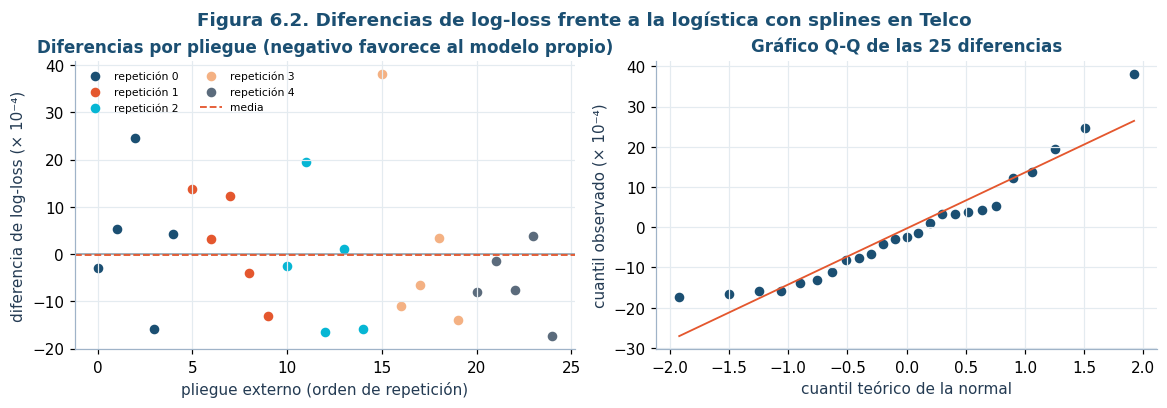

In [6]:
# Diferencias por pliegue (RegionalMAPEM − logística con splines) y su ajuste a la normal
P = POR_PLIEGUE[POR_PLIEGUE.conjunto == "telco"].pivot_table(index=["rep", "pliegue"], columns="modelo", values="log_loss")
d = (P["RegionalMAPEM"] - P[MEJOR]).to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), layout="constrained")
reps = P.index.get_level_values("rep")
for r in range(5):
    ax[0].scatter(np.where(reps == r)[0], d[reps == r] * 1e4, label=f"repetición {r}", s=28)
ax[0].axhline(0, color=GRIS, lw=1); ax[0].axhline(d.mean() * 1e4, color=RIESGO, lw=1.2, ls="--", label="media")
ax[0].set(xlabel="pliegue externo (orden de repetición)", ylabel="diferencia de log-loss (× 10⁻⁴)",
          title="Diferencias por pliegue (negativo favorece al modelo propio)")
ax[0].legend(fontsize=7, ncol=2)
(osm, osr), (pend, inter, _) = stats.probplot(d, dist="norm")
ax[1].scatter(osm, osr * 1e4, color=AZUL, s=28); ax[1].plot(osm, (pend * osm + inter) * 1e4, color=RIESGO, lw=1.2)
ax[1].set(xlabel="cuantil teórico de la normal", ylabel="cuantil observado (× 10⁻⁴)", title="Gráfico Q-Q de las 25 diferencias")
fig.suptitle("Figura 6.2. Diferencias de log-loss frente a la logística con splines en Telco", color=AZUL, fontweight="bold")
plt.show()

Las diferencias se reparten a ambos lados del cero sin un patrón por repetición. Shapiro-Wilk no rechaza la normalidad
(p = 0,053), aunque queda cerca del límite, y la asimetría es moderada (0,97), con una cola hacia diferencias positivas.
Por eso no nos apoyamos en una sola prueba: la permutación de signos no supone normalidad y llega a la misma conclusión.

### Ablación

La ablación responde de dónde viene el desempeño del modelo. Cada variante quita una pieza: el prior hacia los pesos
globales, las regiones (pesos globales, $K = 1$), las pertenencias suaves (regiones duras), o todo el aprendizaje de pesos
(promedio simple). El stacking logístico es la alternativa clásica para combinar expertos.

In [7]:
# Ablación en Telco: RegionalMAPEM frente a cada variante (bloque A2 de la familia de Holm)
A = FAM[FAM.bloque == "A2_principal_ablacion"]
filas = []
for rival, g in A.groupby("modelo_b", sort=False):
    t1 = g[g.prueba == "T1"].iloc[0]
    filas.append({"Variante": NOMBRES[rival], "Diferencia de log-loss (original − variante)": t1.dif_media,
                  "IC 95 % (BCa)": f"[{numero(t1.ic_bajo, 5)}; {numero(t1.ic_alto, 5)}]",
                  "Pliegues en que gana el original": f"{int(t1.pliegues_gana)} de 25", "δ de Cliff": t1.cliff, "Magnitud": t1.magnitud,
                  "p Holm (Nadeau-Bengio)": t1.p_holm, "p Holm (permutación)": g[g.prueba == "T2"].p_holm.iloc[0],
                  "p Holm (Wilcoxon)": g[g.prueba == "T4"].p_holm.iloc[0]})
tabla(pd.DataFrame(filas), "Tabla 6.5. Ablación de RegionalMAPEM en Telco", decimales=5,
      columnas_p=("p Holm (Nadeau-Bengio)", "p Holm (permutación)", "p Holm (Wilcoxon)"))

Variante,Diferencia de log-loss (original − variante),IC 95 % (BCa),Pliegues en que gana el original,δ de Cliff,Magnitud,p Holm (Nadeau-Bengio),p Holm (permutación),p Holm (Wilcoxon)
MAP-EM sin prior,"−0,00043","[−0,00075; −0,00020]",22 de 25,"−0,03360",despreciable,"1,0000","0,7939","0,0382"
Pesos globales (K = 1),"0,00033","[0,00010; 0,00068]",12 de 25,"0,02400",despreciable,"1,0000","1,0000","1,0000"
Regiones duras,"−0,00012","[−0,00027; 6,65e−06]",14 de 25,"−0,02240",despreciable,"1,0000","1,0000","1,0000"
Promedio simple,"−0,00394","[−0,00478; −0,00305]",24 de 25,"−0,24160",pequeño,"0,2828","0,0131","2,11e−05"
Stacking logístico,"0,00011","[−0,00033; 0,00052]",9 de 25,"0,01120",despreciable,"1,0000","1,0000","1,0000"


La ablación es la parte más reveladora del capítulo:

- **El prior importa.** Sin él, el modelo empeora en 22 de 25 pliegues y Wilcoxon lo confirma después de Holm. Es la
  única pieza propia con un aporte medible, aunque pequeño (0,0004).
- **Las regiones no aportan.** Los pesos globales ($K = 1$) son mejores en promedio por 0,0003 y ganan en 13 de 25
  pliegues; ninguna prueba distingue entre ambos. Las regiones duras tampoco se distinguen de las suaves.
- **Aprender los pesos sí sirve.** Frente al promedio simple, el modelo gana en 24 de 25 pliegues, con un efecto pequeño
  pero significativo en dos pruebas.
- **El stacking logístico empata.** La alternativa clásica rinde igual.

En otras palabras, el valor del modelo en Telco está en combinar expertos calibrados con pesos aprendidos, no en hacerlo
por regiones. El prior funciona como se diseñó: cuando las regiones no tienen nada que aportar, empuja los pesos de cada
región hacia los globales y evita que el modelo pierda por sobreajuste. El capítulo 7 muestra la misma conclusión desde
el estudio de sensibilidad.

### Comparación bayesiana (exploratoria)

La prueba bayesiana de rangos con signo {cite}`benavoli2017` no estaba entre las confirmatorias, pero contesta una pregunta que las pruebas
frecuentistas no contestan: ¿qué tan probable es que los modelos sean prácticamente equivalentes? Usamos una región de
equivalencia práctica (ROPE) de ±0,001 de log-loss.

In [8]:
# Probabilidades a posteriori con ROPE de 0,001 en log-loss (exploratorio)
B = pd.read_csv(TAB / "bayesiana_rope.csv")
B = B[B.conjunto == "telco"].sort_values("p_equivalentes", ascending=False)
tabla(pd.DataFrame({"Rival": B.rival.map(NOMBRES), "P(original mejor)": B.p_original_mejor,
                    "P(equivalentes)": B.p_equivalentes, "P(rival mejor)": B.p_rival_mejor}),
      "Tabla 6.6. Prueba bayesiana de rangos con signo en Telco (ROPE = 0,001)", decimales=3)

Rival,P(original mejor),P(equivalentes),P(rival mejor)
Regiones duras,"0,000","1,000","0,000"
Stacking logístico,"5,00e−05","1,000","2,00e−04"
MAP-EM sin prior,"3,00e−04","1,000","0,000"
Pesos globales (K = 1),"0,000","1,000","3,50e−04"
Logística con splines,"2,00e−04","0,997","0,003"
LightGBM,"0,364","0,636","0,000"
HistGB,"0,904","0,096","0,000"
kNN,"1,000","0,000","0,000"
SVM,"1,000","0,000","0,000"
XGBoost,"1,000","0,000","0,000"


Con la logística con splines, los pesos globales, el stacking y las demás variantes, la probabilidad de equivalencia
práctica supera el 99 %. Frente a HistGB (0,90) y los siete benchmarks clásicos, el modelo propio es mejor con
probabilidad alta; frente a LightGBM, lo más probable vuelve a ser la equivalencia (0,64). El empate con el mejor benchmark no es falta de potencia: los datos favorecen activamente la equivalencia.

## Familia completa de comparaciones

La tabla 6.7 contiene las 223 comparaciones con su p crudo y su p ajustado por Holm. Incluye los benchmarks y la ablación
en Telco, Friedman y Nemenyi, las métricas secundarias, el hold-out, los tres conjuntos adicionales y la prueba entre
conjuntos. Se puede filtrar escribiendo en el buscador.

In [9]:
# Las 223 comparaciones; resumen por bloque y tabla completa
BLOQUE = {"A1_principal_benchmarks": "A1. Telco, frente a benchmarks", "A2_principal_ablacion": "A2. Telco, ablación",
          "A3_principal_friedman": "A3. Telco, Friedman y Nemenyi", "B_principal_secundarias": "B. Telco, F1 y AUC",
          "C_holdout": "C. Hold-out", "D_adicionales": "D. Conjuntos adicionales", "E_entre_conjuntos": "E. Entre conjuntos"}
res = FAM.groupby("bloque").agg(n=("id", "size"), calc=("calculada", "sum"), rech=("p_holm", lambda p: int((p < 0.05).sum()))).reset_index()
tabla(pd.DataFrame({"Bloque": res.bloque.map(BLOQUE), "Comparaciones": res.n, "Calculadas": res.calc.astype(int),
                    "Rechazos con Holm (p < 0,05)": res.rech}), "Tabla 6.7a. Familia de Holm por bloque", buscar=False)
vista = pd.DataFrame({"Id": FAM.id, "Bloque": FAM.bloque.map(BLOQUE), "Conjunto": FAM.dataset.map(CONJUNTOS),
                      "Métrica": FAM.metrica.map(METRICA | {"rango_log_loss": "Rango de log-loss"}),
                      "Prueba": FAM.prueba.map(NOMBRE_PRUEBA | {"T3_friedman": "Friedman (Iman-Davenport)", "wilcoxon": "Wilcoxon entre conjuntos",
                                                                 "friedman_iman_davenport": "Friedman entre conjuntos"}),
                      "Rival": FAM.modelo_b.map(NOMBRES | {"todos": "Todos"}), "Estadístico": FAM.estadistico,
                      "p crudo": FAM.p_crudo, "p Holm": FAM.p_holm, "δ de Cliff": FAM.cliff})
tabla(vista, "Tabla 6.7b. Las 223 comparaciones de la familia confirmatoria", decimales=4, columnas_p=("p crudo", "p Holm"))

Bloque,Comparaciones,Calculadas,"Rechazos con Holm (p < 0,05)"
"A1. Telco, frente a benchmarks",33,33,20
"A2. Telco, ablación",15,15,3
"A3. Telco, Friedman y Nemenyi",17,17,8
"B. Telco, F1 y AUC",44,44,12
C. Hold-out,3,3,0
D. Conjuntos adicionales,99,99,66
E. Entre conjuntos,12,12,1


Id,Bloque,Conjunto,Métrica,Prueba,Rival,Estadístico,p crudo,p Holm,δ de Cliff
1,"A1. Telco, frente a benchmarks",Telco,Log-loss,t corregida de Nadeau-Bengio,kNN,"−9,7680","7,76e−10","1,61e−07","−0,8144"
2,"A1. Telco, frente a benchmarks",Telco,Log-loss,Permutación pareada de signos (100 000),kNN,"−0,0192","1,00e−05","0,0016","−0,8144"
3,"A1. Telco, frente a benchmarks",Telco,Log-loss,Wilcoxon de rangos con signo,kNN,"0,0000","5,96e−08","1,22e−05","−0,8144"
4,"A1. Telco, frente a benchmarks",Telco,Log-loss,t corregida de Nadeau-Bengio,Naive Bayes,"−13,5252","1,01e−12","2,16e−10","−1,0000"
5,"A1. Telco, frente a benchmarks",Telco,Log-loss,Permutación pareada de signos (100 000),Naive Bayes,"−0,0366","1,00e−05","0,0016","−1,0000"
6,"A1. Telco, frente a benchmarks",Telco,Log-loss,Wilcoxon de rangos con signo,Naive Bayes,"0,0000","5,96e−08","1,22e−05","−1,0000"
7,"A1. Telco, frente a benchmarks",Telco,Log-loss,t corregida de Nadeau-Bengio,Logística,"−3,3399","0,0027","0,2623","−0,3504"
8,"A1. Telco, frente a benchmarks",Telco,Log-loss,Permutación pareada de signos (100 000),Logística,"−0,0058","5,00e−05","0,0061","−0,3504"
9,"A1. Telco, frente a benchmarks",Telco,Log-loss,Wilcoxon de rangos con signo,Logística,"5,0000","5,96e−07","1,03e−04","−0,3504"
10,"A1. Telco, frente a benchmarks",Telco,Log-loss,t corregida de Nadeau-Bengio,Árbol de decisión,"−7,1840","2,01e−07","3,51e−05","−0,8592"


De las 223 comparaciones, 110 rechazan la hipótesis nula después de Holm. Casi todas son victorias del modelo propio
frente a benchmarks individuales, en Telco y en los conjuntos adicionales. Ninguna es una victoria significativa frente
al mejor benchmark de Telco, que es la que decide R3.

La prueba entre conjuntos tiene una limitación de diseño que conviene decir con claridad: con solo cuatro conjuntos, el
Wilcoxon por pares no puede bajar de p = 0,125, aun si el modelo gana en los cuatro. Por eso ninguna de esas once
comparaciones rechaza, aunque el modelo propio tiene menor log-loss medio que la mayoría de los benchmarks en los cuatro
conjuntos. Friedman entre conjuntos sí rechaza la igualdad global (p de Holm = 6 × 10⁻⁵).

## Veredicto sobre R3

La definición operativa de superioridad exige cuatro condiciones a la vez.

In [10]:
# Las cuatro condiciones de R3 (sección 9 del protocolo)
h2 = VEREDICTO["H2"]
ganados = sum(v["mejor_en_media"] for v in h2.values())
filas = [
    {"Condición": "1. Log-loss medio menor que el del mejor benchmark y el de cada modelo base",
     "Resultado": f"{numero(VEREDICTO['log_loss_original'], 5)} frente a {numero(VEREDICTO['log_loss_mejor_benchmark'], 5)} ({NOMBRES[MEJOR]})",
     "¿Se cumple?": VEREDICTO["condicion_1"]},
    {"Condición": "2. Al menos tres pruebas distintas rechazan H0 con Holm",
     "Resultado": f"{sum(VEREDICTO['rechazos'].values())} de 4 (Nadeau-Bengio, permutación, Wilcoxon, Nemenyi)",
     "¿Se cumple?": VEREDICTO["condicion_2"]},
    {"Condición": "3. |δ de Cliff| ≥ 0,147 a favor del modelo propio",
     "Resultado": f"δ = {numero(VEREDICTO['cliff'], 3)}", "¿Se cumple?": VEREDICTO["condicion_3"]},
    {"Condición": "4. Mejor en media en al menos 2 de los 3 conjuntos adicionales y nunca significativamente peor",
     "Resultado": f"mejor en {ganados} de 3; significativamente peor en {sum(v['significativamente_peor'] for v in h2.values())}",
     "¿Se cumple?": VEREDICTO["condicion_4"]},
]
tabla(pd.DataFrame(filas), "Tabla 6.8. Condiciones de superioridad (R3)", buscar=False)
nota(f"<b>R3 {'alcanzado' if VEREDICTO['R3'] else 'no alcanzado'}.</b> Solo se cumple la condición 1, por un margen "
     "de 0,00003 que ninguna prueba distingue del azar.", "ok" if VEREDICTO["R3"] else "warn")

Condición,Resultado,¿Se cumple?
1. Log-loss medio menor que el del mejor benchmark y el de cada modelo base,"0,41127 frente a 0,41130 (Logística con splines)",Sí
2. Al menos tres pruebas distintas rechazan H0 con Holm,"0 de 4 (Nadeau-Bengio, permutación, Wilcoxon, Nemenyi)",No
"3. |δ de Cliff| ≥ 0,147 a favor del modelo propio","δ = −0,008",No
4. Mejor en media en al menos 2 de los 3 conjuntos adicionales y nunca significativamente peor,mejor en 1 de 3; significativamente peor en 0,No


El modelo propio no supera al mejor benchmark. Tampoco pierde: en ningún conjunto es significativamente peor que el
mejor benchmark de ese conjunto, y en todos supera con claridad a buena parte de los modelos individuales. Pero la
superioridad que pide R3 exige más que un empate favorable.

La causa probable no es falta de potencia ni de presupuesto. Los 25 pliegues bastan para detectar diferencias de 0,0004
(como la del prior), y la prueba bayesiana favorece la equivalencia con más del 99 % de probabilidad. La explicación está
en la ablación y en la sensibilidad: en Telco, la fiabilidad relativa de los expertos casi no cambia entre tipos de
cliente, así que dividir en regiones no deja nada que aprovechar. Con un único vector de pesos, el modelo se reduce a un
buen ensamble ponderado, y ese ensamble rinde lo mismo que la logística con splines, que ya captura la mayor parte de la
señal disponible en este conjunto. El capítulo 9 retoma esta discusión.